In [ ]:
!mkdir -p ~/.kaggle

In [ ]:
!cp kaggle.json ~/.kaggle

In [ ]:
!kaggle dataset download -d hojjatk/mnist-dataset

In [ ]:
!unzip -q mnist-dataset.zip -d mnist/

In [13]:
import pandas as pd

In [14]:
pip install idx2numpy

  Preparing metadata (setup.py) ... done
  Created wheel for idx2numpy: filename=idx2numpy-1.2.3-py3-none-any.whl size=7999 sha256=8702ffe81bc9d74f197d8813db6d4e00824a975af5eab4b412784ae66b55cc25
  Stored in directory: /root/.cache/pip/wheels/3a/19/2b/d62d9c881cc383ad62fc12a882040d1900c19b5115b6a41e50
Successfully built idx2numpy


In [15]:
import idx2numpy
import numpy as np

In [16]:
train_image_path="/content/mnist/train-images.idx3-ubyte"
train_image_label_path="/content/mnist/train-labels.idx1-ubyte"

In [17]:
x_train=idx2numpy.convert_from_file(train_image_path)
y_train=idx2numpy.convert_from_file(train_image_label_path)

In [19]:
x_train.shape

(60000, 28, 28)

In [20]:
y_train.shape

(60000,)

In [21]:
num_images = x_train.shape[0]
x_train_flat = x_train.reshape(num_images, -1)

In [22]:
df = pd.DataFrame(x_train_flat)

In [23]:
df.insert(0,'label',y_train)

In [24]:
df.to_csv('mnist_train.csv',index=False)

In [25]:
df.shape

(60000, 785)

In [27]:
df.sample(10)

,label,0,1,2,3,4,5,6,7,8,...,774,775,776,777,778,779,780,781,782,783
18506,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
54843,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
16823,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2444,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5871,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
31045,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
28277,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
38236,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
26312,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
22922,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [29]:
import matplotlib.pyplot as plt

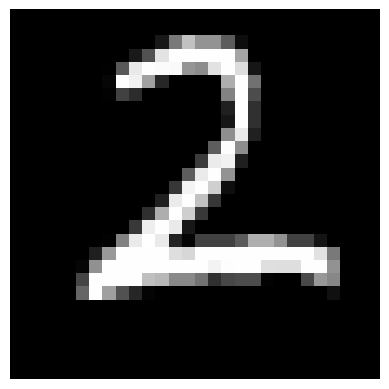

In [41]:
plt.imshow(df.iloc[22922,1:].values.reshape(28,28), cmap='gray')
plt.axis('off')
plt.show()

In [47]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [48]:
X

,0,1,2,3,4,5,6,7,8,9,...,774,775,776,777,778,779,780,781,782,783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59996,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59997,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59998,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [50]:
from sklearn.model_selection import train_test_split

In [90]:
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [58]:
x_train.shape

(48000, 784)

In [59]:
y_train.shape

(48000,)

In [54]:
from sklearn.neighbors import KNeighborsClassifier

In [91]:
knn=KNeighborsClassifier()

In [60]:
knn.fit(x_train,y_train)

KNeighborsClassifier()

In [61]:
y_pred =  knn.predict(x_test)

In [64]:
from sklearn.metrics import accuracy_score

In [65]:
accuracy_score(y_test,y_pred)

0.9715

## Now Comming to the PCA Part

In [66]:
from sklearn.preprocessing import StandardScaler

In [92]:
scaler = StandardScaler()

In [80]:
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [93]:
from sklearn.decomposition import PCA

In [82]:
pca = PCA(n_components=200)

In [83]:
x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)

In [84]:
x_train_trf.shape

(48000, 200)

In [85]:
knn.fit(x_train_trf,y_train)

KNeighborsClassifier()

In [86]:
y_predict = knn.predict(x_test_trf)

In [87]:
accuracy_score(y_test,y_predict)

0.955

In [96]:
for i in range(1,784):
  x_train = scaler.fit_transform(x_train)
  x_test = scaler.transform(x_test)

  pca = PCA(n_components=i)

  x_train_trf = pca.fit_transform(x_train)
  x_test_trf = pca.transform(x_test)

  knn.fit(x_train_trf,y_train)

  y_predict = knn.predict(x_test_trf)

  print(i,accuracy_score(y_test,y_predict))

1 0.2628333333333333
2 0.3164166666666667
3 0.5074166666666666
4 0.6633333333333333
5 0.7405833333333334
6 0.8254166666666667
7 0.8383333333333334
8 0.8724166666666666
9 0.88475
10 0.9083333333333333
11 0.9154166666666667
12 0.9196666666666666
13 0.92725
14 0.9359166666666666
15 0.9404166666666667
16 0.9421666666666667
17 0.9429166666666666
18 0.94425
19 0.9475
20 0.9501666666666667
21 0.9499166666666666
22 0.9494166666666667
23 0.9515833333333333
24 0.9528333333333333
25 0.9535
26 0.9538333333333333
27 0.9545
28 0.9549166666666666
29 0.95525
30 0.95675
31 0.9563333333333334
32 0.9571666666666667
33 0.9571666666666667
34 0.9578333333333333
35 0.958
36 0.9576666666666667
37 0.957
38 0.9575833333333333
39 0.9581666666666667
40 0.95725
41 0.9576666666666667
42 0.95775
43 0.9579166666666666
44 0.95825
45 0.958
46 0.9583333333333334
47 0.95825
48 0.95925
49 0.9591666666666666
50 0.95975
51 0.96
52 0.9595833333333333
53 0.9599166666666666
54 0.9593333333333334
55 0.95925
56 0.959166666666666

KeyboardInterrupt: 

In [104]:
import plotly.express as px

In [98]:
pca = PCA(n_components=2)

x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)

In [99]:
x_train_trf.shape

(48000, 2)

In [112]:
x_test_trf.shape

(12000, 2)

In [109]:
y_train_trf=y_train.astype(str)

In [114]:
fig = px.scatter(
    x=x_train_trf[:,0],
    y=x_train_trf[:,1],
    color=y_train_trf,
    title="2D PCA Visualization"
)

fig.update_traces(marker=dict(size=8, opacity=0.8))
fig.show()

In [115]:
pca = PCA(n_components=3)

x_train_trf = pca.fit_transform(x_train)
x_test_trf = pca.transform(x_test)

In [116]:
y_train_trf = y_train.astype(str)
fig = px.scatter_3d(
    x=x_train_trf[:,0],
    y=x_train_trf[:,1],
    z=x_train_trf[:,2],
    color=y_train_trf,
    title="3D PCA Visualization"
)

fig.show()